In [1]:
# Import all functions from the required modules
from cordo_sherpa_module import *
from cordo_chimere_module import *
from expo_functions_module import *
#from association_module import *
print("Successfully loaded all modules")

Successfully loaded all modules


In [2]:
# Paths to the files
path_fichier_shp = "data/2-output-data/donnees_shp"
title_shp = "donnees_insee_iris"
path_fichier_pourcents = "data/2-output-data"
title_pourcents = "pourcents"

# Load the concentration points
scenario = "s1"
pollutant = "ug_PM25_RH50"
conc_points = coordo_chimere(pollutant, year=2019, SC=scenario.upper())
# Load the exported data
donnees_exportees = gpd.read_file(os.path.join(path_fichier_shp, f"{title_shp}.shp"))

# Transform the CRS of the exported data to match the concentration points
donnees_exportees_transformed = donnees_exportees.to_crs(epsg=conc_points.crs.to_epsg())

# Check if CRSs are the same
if conc_points.crs == donnees_exportees_transformed.crs:
    print("CRS for conc_points_transformed and donnees_exportees_transformed are the same.")
else:
    print("CRS for conc_points_transformed and donnees_exportees_transformed are different.")

Starting coordo_chimere function
Loading data from data\1-processed-data\SHERPA\CHIMERE\outl.2019_FRA02_PM25_analysis_yravg.nc
Finished processing coordo_chimere function
CRS for conc_points_transformed and donnees_exportees_transformed are the same.


In [3]:
import geopandas as gpd
from shapely.geometry import Polygon
import pandas as pd
from geopandas import GeoDataFrame
from shapely.ops import unary_union
import multiprocessing
from functools import partial
import os
from shapely.geometry import box

def generate_points(polygone, conc_points):
    """
    Generate grid points for a given polygon and associate them with concentration points
    based on rectangle-polygon intersection instead of centroid inclusion.
    """
    if polygone.geometry.is_empty or not polygone.geometry.is_valid:
        return gpd.GeoDataFrame()
    if conc_points is None or conc_points.empty:
        return gpd.GeoDataFrame()

    polygon_geom = polygone.geometry
    # Build rectangles around all points
    rect_geoms = conc_points.geometry.apply(
        lambda pt: Polygon([
            (pt.x - 0.05, pt.y - 0.025),
            (pt.x + 0.05, pt.y - 0.025),
            (pt.x + 0.05, pt.y + 0.025),
            (pt.x - 0.05, pt.y + 0.025),
            (pt.x - 0.05, pt.y - 0.025)
        ])
    )
    rect_gdf = gpd.GeoDataFrame(
        conc_points.drop(columns="geometry").copy(),
        geometry=rect_geoms,
        crs=conc_points.crs
    )
    # Fast spatial filtering: keep rectangles that intersect the polygon (don't work on centroid)
    intersects_mask = rect_gdf.intersects(polygon_geom)
    points_within = conc_points.loc[intersects_mask].copy()
    points_within["iriscod"] = polygone["iriscod"]
    return points_within


import geopandas as gpd
from shapely.geometry import box
def calculate_intersection_percentages(
    grille_points: gpd.GeoDataFrame,
    iris_polygons: gpd.GeoDataFrame,
    cell_size_m: float = 1000.0,
    denominator: str = "cell",   # "cell" or "iris"
):
    if grille_points.crs != iris_polygons.crs:
        raise ValueError(f"CRS mismatch: grille={grille_points.crs}, iris={iris_polygons.crs}")
    if "iriscod" not in grille_points.columns:
        raise ValueError("grille_points must contain 'iriscod'")

    half = cell_size_m / 2.0

    g = grille_points.copy()
    iris = iris_polygons[["iriscod", "geometry"]].copy()

    # Build cell polygons around each point
    xs = g.geometry.x.to_numpy()
    ys = g.geometry.y.to_numpy()
    cell_geom = [box(x-half, y-half, x+half, y+half) for x, y in zip(xs, ys)]
    g["cell_geom"] = cell_geom

    # attach IRIS geometry
    g = g.merge(iris, on="iriscod", how="left", suffixes=("", "_iris"))

    # IMPORTANT: make them GeoSeries so .intersection works
    cell_gs = gpd.GeoSeries(g["cell_geom"], crs=g.crs)
    iris_gs = gpd.GeoSeries(g["geometry_iris"], crs=g.crs)

    inter_area = cell_gs.intersection(iris_gs).area

    if denominator == "cell":
        denom = float(cell_size_m * cell_size_m)
    elif denominator == "iris":
        denom = iris_gs.area
    else:
        raise ValueError("denominator must be 'cell' or 'iris'")

    g["perc"] = (inter_area / denom).astype(float)

    g = g[g["perc"] > 0].copy()
    g = g.drop(columns=["cell_geom", "geometry_iris"])
    return g

def process_subset(subset, conc_points):
    """
    Process a subset of polygons with concentration points.
    """
    subset_results = []
    for idx, row in subset.iterrows():
        points = generate_points(row, conc_points)
        subset_results.append(points)

    return GeoDataFrame(pd.concat(subset_results, ignore_index=True) if subset_results else [])

def worker_function(donnees_subset, conc_points):
    """
    Wrapper to process subsets of polygons using multiprocessing.
    """
    try:
        return process_subset(donnees_subset, conc_points)
    except Exception as e:
        print(f"Worker function error: {e}")
        return gpd.GeoDataFrame()


def association(donnees_exportees_transformed, conc_points):
    """
    Perform the association operation and return the resulting GeoDataFrame.
    """
    # Ensure input GeoDataFrames are valid and CRS is assigned
    if not isinstance(donnees_exportees_transformed, GeoDataFrame):
        raise TypeError("donnees_exportees_transformed must be a GeoDataFrame")
    if not isinstance(conc_points, GeoDataFrame):
        raise TypeError("conc_points must be a GeoDataFrame")

    if donnees_exportees_transformed.crs is None or conc_points.crs is None:
        # Assign default CRS if missing
        print("Assigning default CRS 'EPSG:4326' to inputs...")
        donnees_exportees_transformed.set_crs("EPSG:4326", inplace=True)
        conc_points.set_crs("EPSG:4326", inplace=True)

    # Split the data into smaller subsets for multiprocessing
    num_cores = multiprocessing.cpu_count()
    subset_size = max(1, len(donnees_exportees_transformed) // num_cores)
    subsets = [
        donnees_exportees_transformed.iloc[i:i + subset_size]
        for i in range(0, len(donnees_exportees_transformed), subset_size)
    ]

    if not subsets:
        print("No subsets created. Returning empty GeoDataFrame.")
        return GeoDataFrame()

    # Use multiprocessing to process the subsets
    with multiprocessing.Pool(num_cores) as pool:
        worker_func = partial(worker_function, conc_points=conc_points)
        grids = pool.map(worker_func, subsets)

    grids = [grid for grid in grids if not grid.empty]

    # If grids are empty after filtering, return an empty GeoDataFrame
    if not grids:
        print("No grids generated. Returning empty GeoDataFrame.")
        return GeoDataFrame()

    # Combine results into a single GeoDataFrame
    result = GeoDataFrame(pd.concat(grids, ignore_index=True))
    result = result.to_crs(2154)
    donnees_exportees_transformed = donnees_exportees_transformed.to_crs(2154)

    # Calculate intersection percentages finally
    result = calculate_intersection_percentages(result, donnees_exportees_transformed, 1000, denominator="iris")
    result = result.to_crs(4326)
    return result

In [ ]:
# Function to export Pourcent shapefile**
def main(base_path="data/2-output-data/pourcent"):
    # Execute the association function
    result = association(
    donnees_exportees_transformed,
    conc_points
    )
    # Check if CRS is defined; if not, assign a default CRS
    if result.crs is None:
        print("CRS not defined for the result. Assigning default CRS 'EPSG:4326'...")
        result.set_crs("WGS84", inplace=True)  # Assign WGS84 (this can be changed)

    # Save the result to a SHP file in the base path
    os.makedirs(base_path, exist_ok=True)  # Ensure the output directory exists
    output_file = os.path.join(base_path, "pourcents.shp")  # Save as Shapefile
    result.to_file(output_file, driver="ESRI Shapefile")

    # Print or log a message indicating the save location
    print(f"Result successfully saved to {output_file}")
if __name__ == "__main__":
    main()

In [6]:
import geopandas as gpd
import pandas as pd
import numpy as np

new_shp = "data/2-output-data/pourcent/pourcents.shp"
old_shp = "data/2-output-data/pourcent_try/pourcents_try.shp"

g_new = gpd.read_file(new_shp)
g_old = gpd.read_file(old_shp)

# Normalize key
for g in (g_new, g_old):
    g["iriscod"] = g["iriscod"].astype(str).str.strip().str.zfill(9)

print("=== BASIC INFO ===")
print("NEW shape:", g_new.shape)
print("OLD shape:", g_old.shape)
print("NEW CRS:", g_new.crs)
print("OLD CRS:", g_old.crs)

print("\n=== COLUMNS ===")
print("NEW columns:", list(g_new.columns))
print("OLD columns:", list(g_old.columns))

print("\n=== NULL CHECKS ===")
for name, g in [("NEW", g_new), ("OLD", g_old)]:
    print(f"\n{name}")
    print("null iriscod:", g["iriscod"].isna().sum())
    print("null perc:", g["perc"].isna().sum())
    print("null geometry:", g.geometry.isna().sum())
    print("empty geometry:", g.geometry.is_empty.sum())

print("\n=== PERC SUMMARY ===")
for name, g in [("NEW", g_new), ("OLD", g_old)]:
    print(f"\n{name}")
    print(g["perc"].describe())
    print("rows with perc > 0:", (g["perc"] > 0).sum())
    print("rows with perc == 0:", (g["perc"] == 0).sum())
    print("rows with perc < 0:", (g["perc"] < 0).sum())
    print("unique IRIS total:", g["iriscod"].nunique())
    print("unique IRIS with perc > 0:", g.loc[g["perc"] > 0, "iriscod"].nunique())

print("\n=== IRIS COVERAGE COMPARISON ===")
new_iris = set(g_new["iriscod"])
old_iris = set(g_old["iriscod"])
new_pos_iris = set(g_new.loc[g_new["perc"] > 0, "iriscod"])
old_pos_iris = set(g_old.loc[g_old["perc"] > 0, "iriscod"])

print("IRIS in NEW not in OLD:", len(new_iris - old_iris))
print("IRIS in OLD not in NEW:", len(old_iris - new_iris))
print("IRIS with perc>0 in NEW not in OLD:", len(new_pos_iris - old_pos_iris))
print("IRIS with perc>0 in OLD not in NEW:", len(old_pos_iris - new_pos_iris))

print("\nFirst 20 IRIS with perc>0 in NEW not in OLD:")
print(sorted(list(new_pos_iris - old_pos_iris))[:20])

print("\n=== AGGREGATED WEIGHT BY IRIS ===")
new_sum = g_new.groupby("iriscod", as_index=False)["perc"].sum().rename(columns={"perc": "perc_sum_new"})
old_sum = g_old.groupby("iriscod", as_index=False)["perc"].sum().rename(columns={"perc": "perc_sum_old"})

weight_cmp = new_sum.merge(old_sum, on="iriscod", how="outer")
weight_cmp["perc_sum_new"] = weight_cmp["perc_sum_new"].fillna(0)
weight_cmp["perc_sum_old"] = weight_cmp["perc_sum_old"].fillna(0)
weight_cmp["diff"] = weight_cmp["perc_sum_new"] - weight_cmp["perc_sum_old"]

print(weight_cmp["diff"].describe())

different_weights = weight_cmp[np.abs(weight_cmp["diff"]) > 1e-12].copy()
print("IRIS with different total perc sums:", len(different_weights))
print(different_weights.sort_values("diff", key=np.abs, ascending=False).head(20))

print("\n=== DUPLICATION / ROW COUNTS PER IRIS ===")
new_counts = g_new.groupby("iriscod").size().rename("row_count_new").reset_index()
old_counts = g_old.groupby("iriscod").size().rename("row_count_old").reset_index()

count_cmp = new_counts.merge(old_counts, on="iriscod", how="outer").fillna(0)
count_cmp["row_count_diff"] = count_cmp["row_count_new"] - count_cmp["row_count_old"]

print("IRIS with different row counts:", (count_cmp["row_count_diff"] != 0).sum())
print(count_cmp[count_cmp["row_count_diff"] != 0].head(20))

print("\n=== OPTIONAL: SAVE COMPARISON TABLES ===")
# weight_cmp.to_csv("weight_compare.csv", index=False)
# count_cmp.to_csv("rowcount_compare.csv", index=False)
# different_weights.to_csv("different_weight_iris.csv", index=False)

=== BASIC INFO ===
NEW shape: (240278, 8)
OLD shape: (12494, 6)
NEW CRS: EPSG:2154
OLD CRS: EPSG:4326

=== COLUMNS ===
NEW columns: ['y', 'x', 'Times', 'conc', 'pt_idx', 'iriscod', 'perc', 'geometry']
OLD columns: ['conc_2019', 'delta_conc', 'conc', 'iriscod', 'perc', 'geometry']

=== NULL CHECKS ===

NEW
null iriscod: 0
null perc: 0
null geometry: 0
empty geometry: 0

OLD
null iriscod: 0
null perc: 0
null geometry: 0
empty geometry: 0

=== PERC SUMMARY ===

NEW
count    2.402780e+05
mean     4.783767e-02
std      8.807902e-02
min      4.970000e-13
25%      8.223644e-03
50%      2.497461e-02
75%      5.377766e-02
max      1.000000e+00
Name: perc, dtype: float64
rows with perc > 0: 240278
rows with perc == 0: 0
rows with perc < 0: 0
unique IRIS total: 44299
unique IRIS with perc > 0: 44299

OLD
count    12494.000000
mean         0.717769
std          0.252827
min          0.048000
25%          0.529000
50%          0.762000
75%          0.965000
max          1.000000
Name: perc, dtype: 

Shapefile loaded successfully from data/2-output-data/pourcent/pourcents.shp


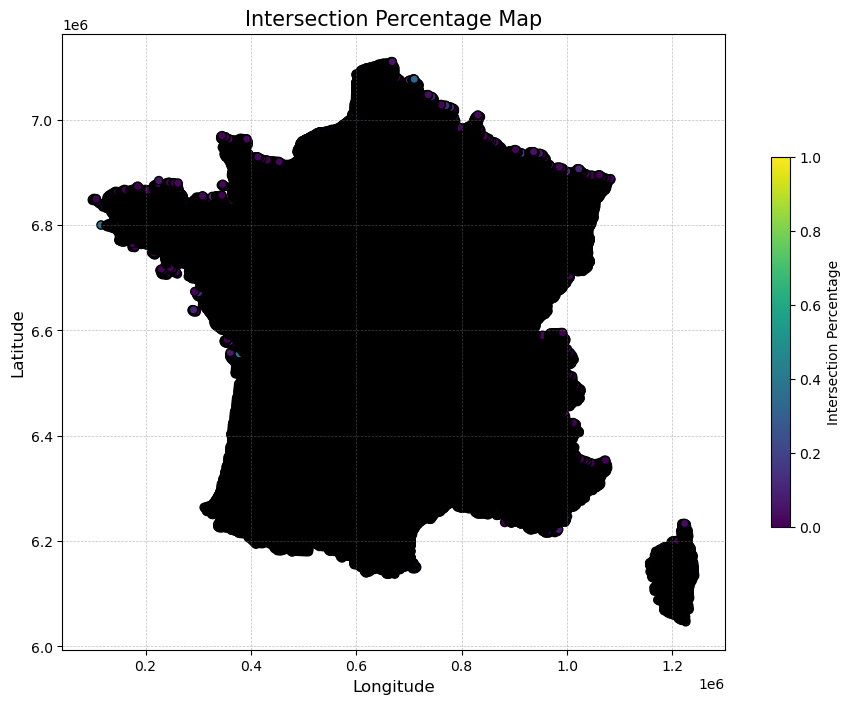

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt

def plot_shapefile(shapefile_path):
    """
    Function to plot a shapefile as a map.
    Args:
        shapefile_path (str): Path to the shapefile to be plotted.
    """
    # Load the shapefile
    try:
        gdf = gpd.read_file(shapefile_path)
        print(f"Shapefile loaded successfully from {shapefile_path}")
    except Exception as e:
        print(f"Error loading shapefile: {e}")
        return

    # Plot the GeoDataFrame
    fig, ax = plt.subplots(figsize=(12, 8))
    gdf.plot(column='perc', ax=ax, legend=True, cmap="viridis", edgecolor="black",
             legend_kwds={'label': "Intersection Percentage", 'shrink': 0.6})

    # Customize the map
    ax.set_title("Intersection Percentage Map", fontsize=15)
    ax.set_xlabel("Longitude", fontsize=12)
    ax.set_ylabel("Latitude", fontsize=12)

    # Show grid lines for better readability
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)

    # Display the map
    plt.show()


if __name__ == "__main__":
    # Path to the exported shapefile (adjust this if needed)
    shapefile_path = "data/2-output-data/pourcent/pourcents.shp"

    # Call the function to plot the shapefile
    plot_shapefile(shapefile_path)